In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
print("Rows, columns:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe(include="all")

Rows, columns: (20640, 10)

Column types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate rows: 0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<1H OCEAN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9136
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909,NaN
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874,NaN
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,NaN
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000,NaN
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000,NaN
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000,NaN


In [4]:
# Remove duplicate rows, if any.
df = df.drop_duplicates().copy()

# Keeping the 207 missing total_bedrooms values for now.
# We'll fill them using the training-set median AFTER splitting, to avoid data leakage.
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


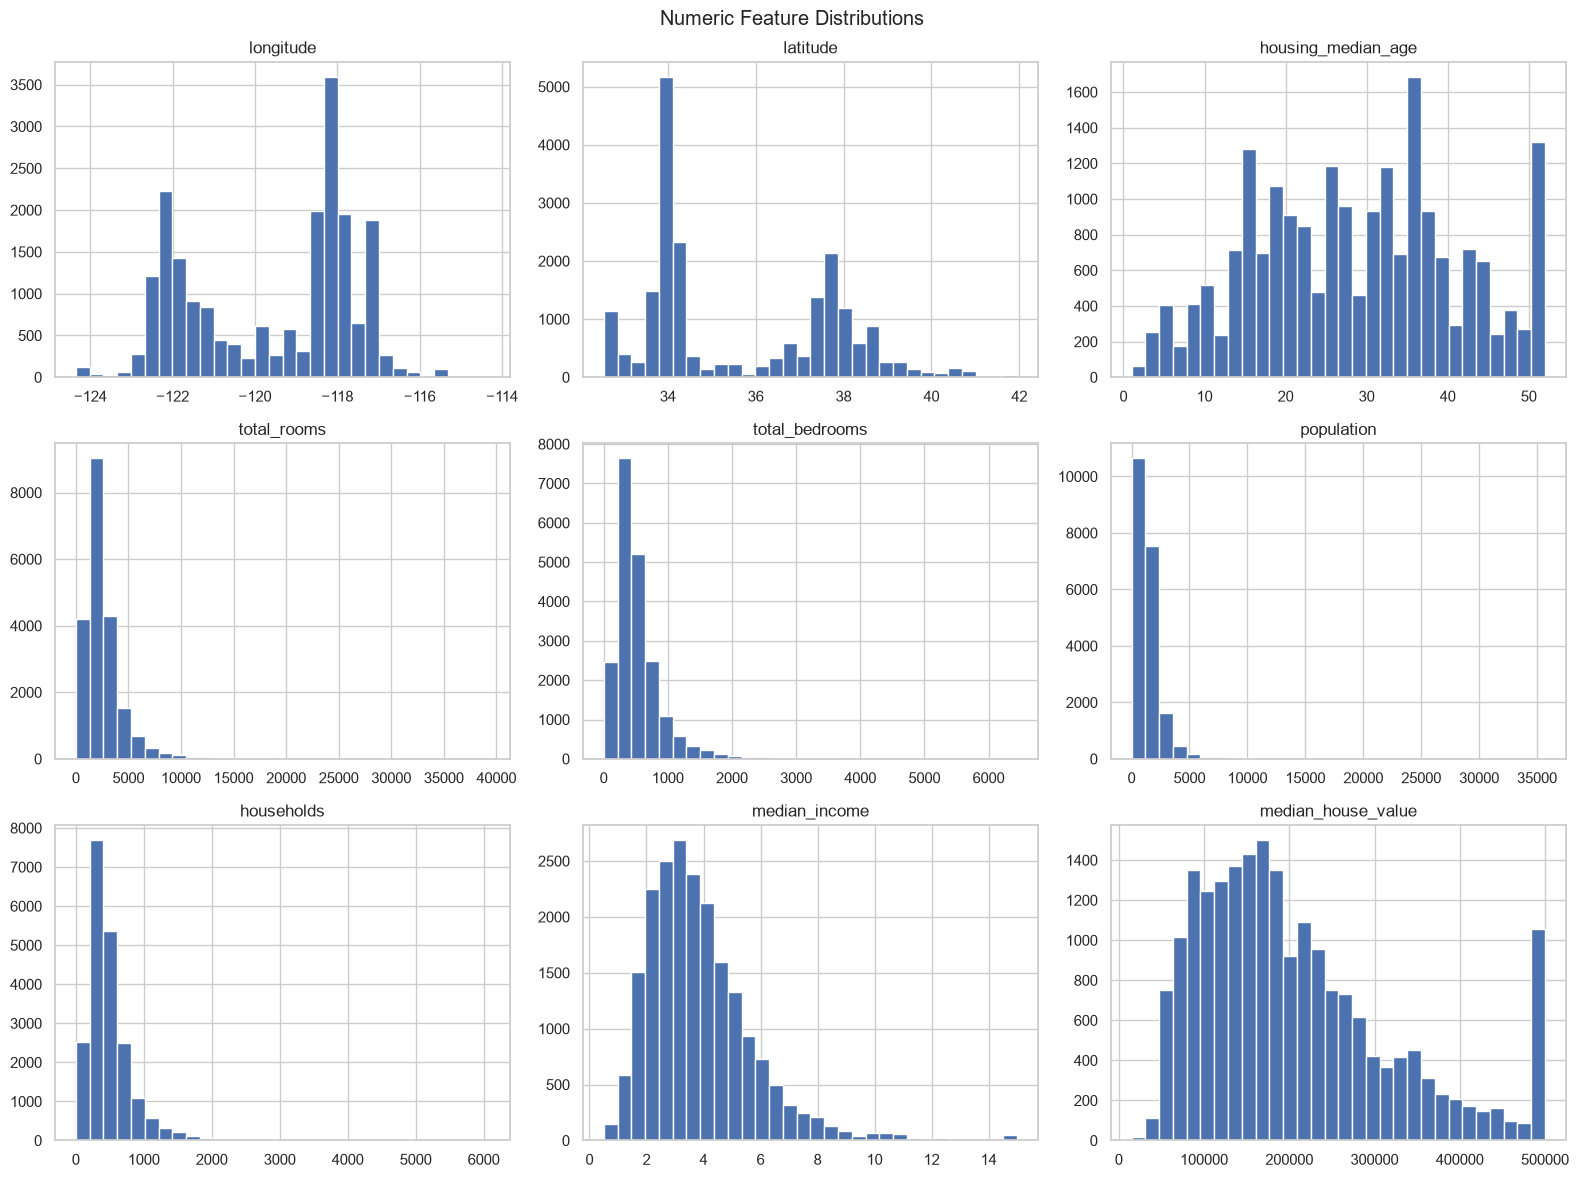

In [5]:
df.hist(bins=30, figsize=(16, 12))
plt.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.show()

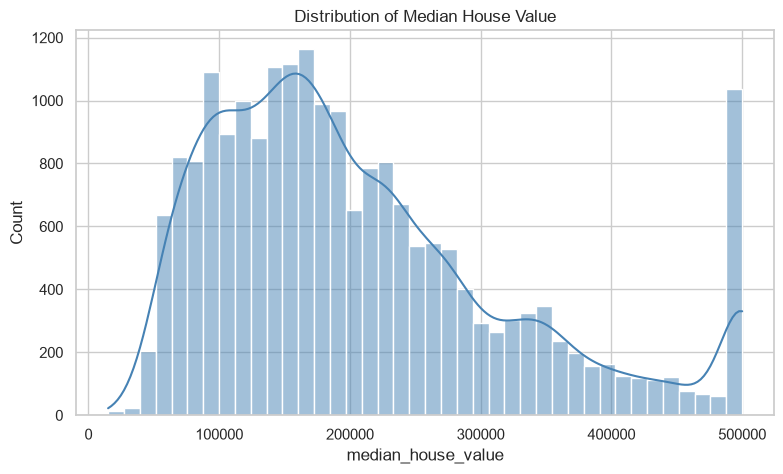

In [6]:
plt.figure(figsize=(9, 5))
sns.histplot(df["median_house_value"], bins=40, kde=True, color="steelblue")
plt.title("Distribution of Median House Value")
plt.show()

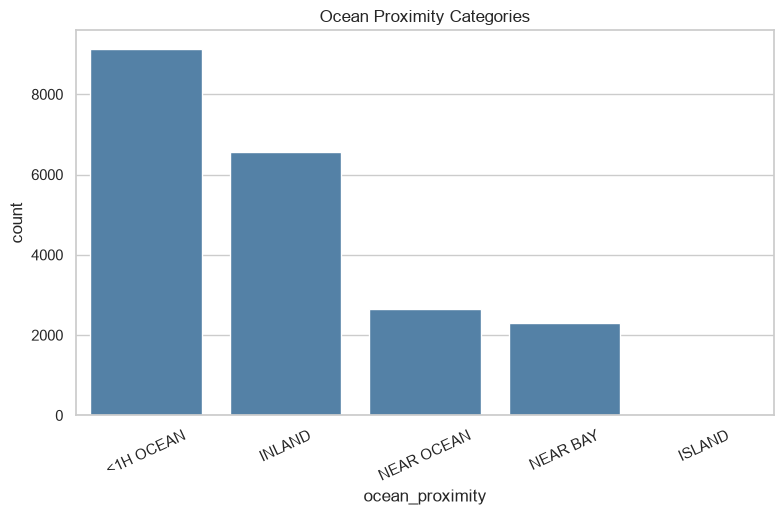

In [7]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="ocean_proximity", order=df["ocean_proximity"].value_counts().index, color="steelblue")
plt.xticks(rotation=25)
plt.title("Ocean Proximity Categories")
plt.show()

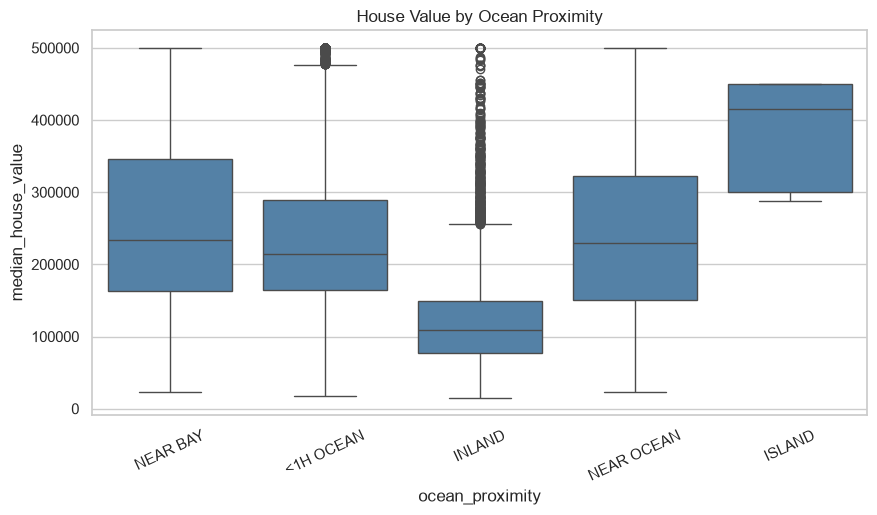

In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="ocean_proximity", y="median_house_value", color="steelblue")
plt.xticks(rotation=25)
plt.title("House Value by Ocean Proximity")
plt.show()

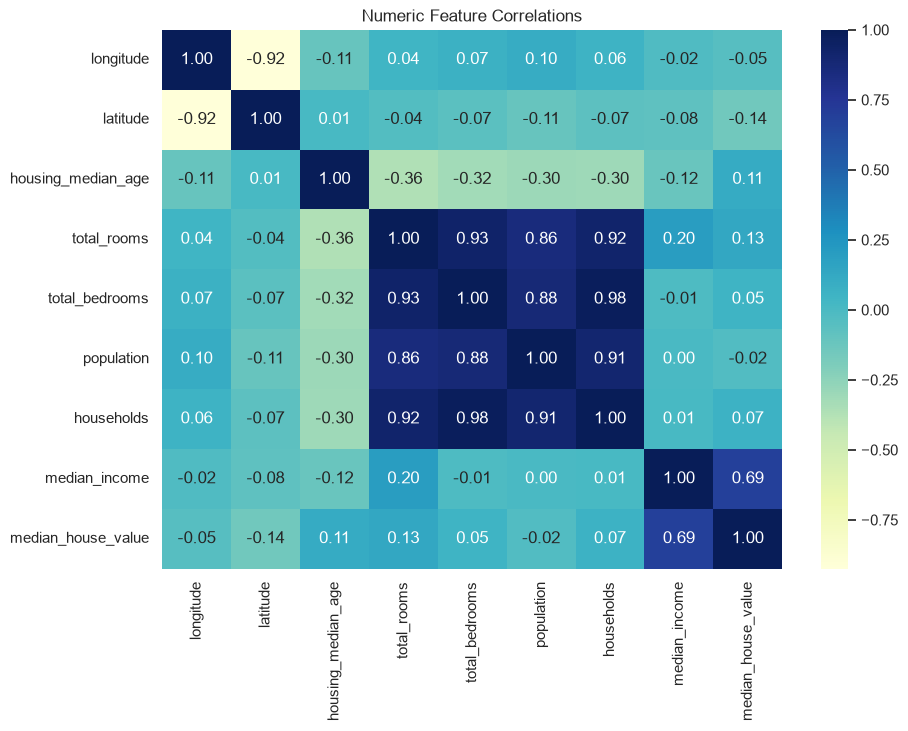

In [9]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Numeric Feature Correlations")
plt.show()

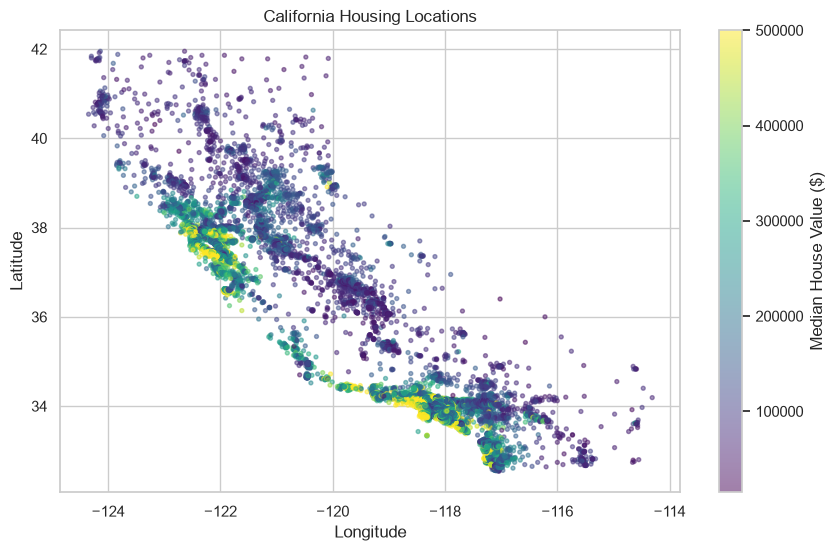

In [10]:
plt.figure(figsize=(10, 6))
plt.scatter(df["longitude"], df["latitude"], c=df["median_house_value"],
            cmap="viridis", s=8, alpha=0.5)
plt.colorbar(label="Median House Value ($)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California Housing Locations")
plt.show()

In [11]:
X = df.drop(columns="median_house_value")
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (16512, 9) Test: (4128, 9)


In [12]:
for data in [X_train, X_test]:
    data["rooms_per_household"] = data["total_rooms"] / data["households"].replace(0, np.nan)
    data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"].replace(0, np.nan)
    data["population_per_household"] = data["population"] / data["households"].replace(0, np.nan)

X_train.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
14196,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596,NEAR OCEAN,5.017657,0.200576,3.691814
8267,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125,NEAR OCEAN,4.473545,0.232703,1.738095
17445,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563,NEAR OCEAN,5.645833,0.174486,2.723214
14265,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425,NEAR OCEAN,4.002817,0.258269,3.994366
2271,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542,INLAND,6.268421,0.180940,2.300000


In [13]:
numeric_columns = X_train.select_dtypes(include="number").columns

imputer = SimpleImputer(strategy="median")
X_train[numeric_columns] = imputer.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = imputer.transform(X_test[numeric_columns])

X_train = pd.get_dummies(X_train, columns=["ocean_proximity"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["ocean_proximity"], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Processed train:", X_train.shape)
print("Any missing train values?", X_train.isnull().sum().sum())

Processed train: (16512, 16)
Any missing train values? 0


In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled training features:", X_train_scaled.shape)

Scaled training features: (16512, 16)


In [15]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
linear_predictions = linear_model.predict(X_test_scaled)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression")
print(f"MAE: ${linear_mae:,.2f}")
print(f"RMSE: ${linear_rmse:,.2f}")
print(f"R²: {linear_r2:.4f}")

Linear Regression
MAE: $49,645.49
RMSE: $69,127.04
R²: 0.6353


In [16]:
forest_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=2, random_state=42, n_jobs=-1
)
forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

print("Random Forest")
print(f"MAE: ${forest_mae:,.2f}")
print(f"RMSE: ${forest_rmse:,.2f}")
print(f"R²: {forest_r2:.4f}")

Random Forest
MAE: $31,874.00
RMSE: $49,698.40
R²: 0.8115


In [17]:
#Comparing models

            Model          MAE         RMSE       R2
Linear Regression 49645.492445 69127.038299 0.635339
    Random Forest 31873.998030 49698.399512 0.811515


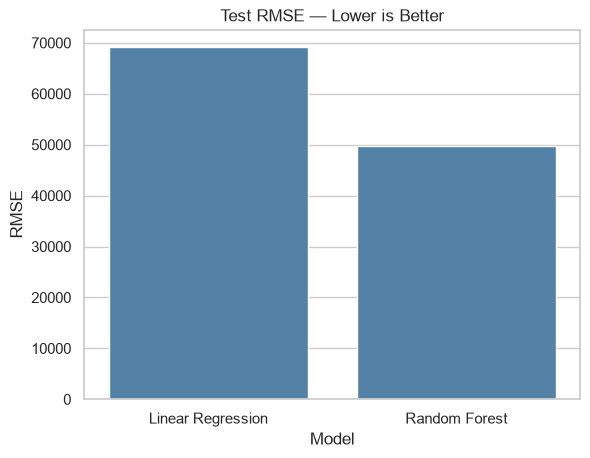

In [18]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, forest_mae],
    "RMSE": [linear_rmse, forest_rmse],
    "R2": [linear_r2, forest_r2]
})
print(results.to_string(index=False))

sns.barplot(data=results, x="Model", y="RMSE", color="steelblue")
plt.title("Test RMSE — Lower is Better")
plt.show()

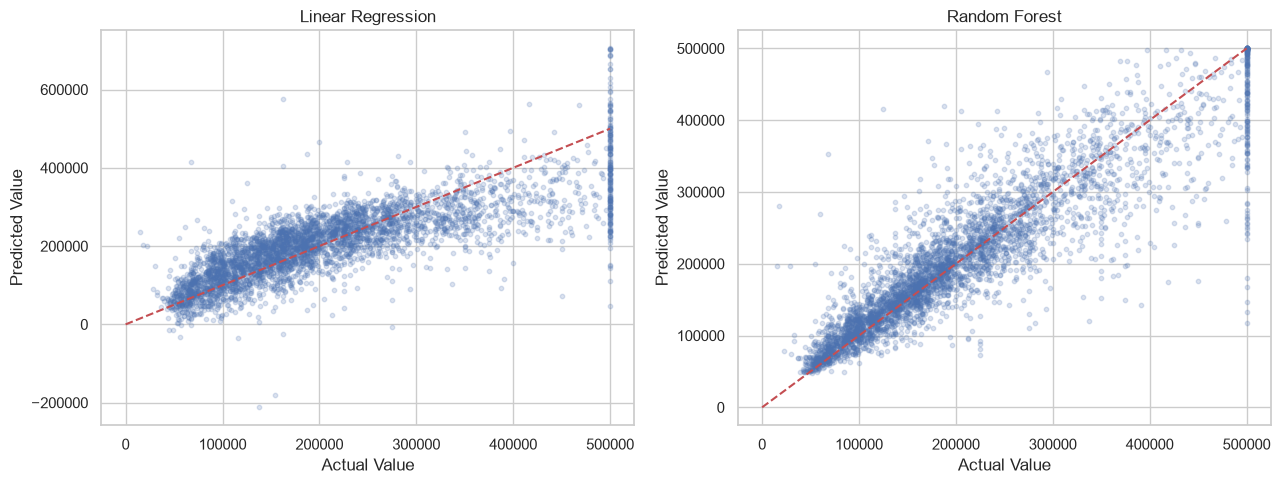

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, predictions, name in zip(axes,
                                 [linear_predictions, forest_predictions],
                                 ["Linear Regression", "Random Forest"]):
    ax.scatter(y_test, predictions, alpha=0.2, s=10)
    ax.plot([0, 500000], [0, 500000], "r--")
    ax.set(title=name, xlabel="Actual Value", ylabel="Predicted Value")
plt.tight_layout()
plt.show()

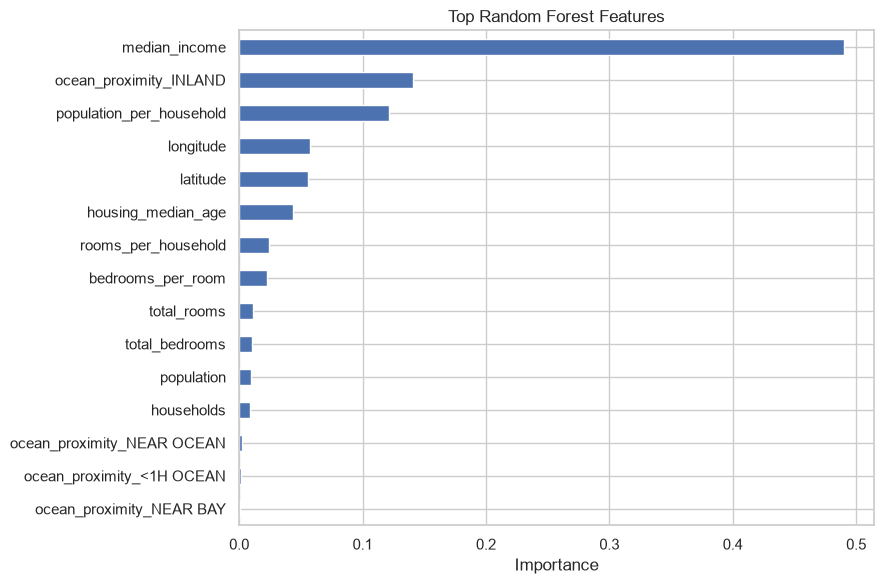

In [20]:
importance = pd.Series(forest_model.feature_importances_, index=X_train.columns)
importance.sort_values().tail(15).plot(kind="barh", figsize=(9, 6))
plt.title("Top Random Forest Features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [21]:
joblib.dump(linear_model, "linear_regression_model.joblib")
joblib.dump(forest_model, "random_forest_model.joblib")
joblib.dump(imputer, "housing_imputer.joblib")
joblib.dump(scaler, "housing_scaler.joblib")
joblib.dump(list(X_train.columns), "housing_feature_columns.joblib")
print("Saved models and preprocessing objects.")

Saved models and preprocessing objects.


In [22]:
sample_results = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Linear Regression": linear_predictions[:10],
    "Random Forest": forest_predictions[:10]
})
sample_results.round(2)

,Actual,Linear Regression,Random Forest
0,47700.0,36496.16,52707.12
1,45800.0,137597.77,69161.89
2,500001.0,293482.55,466728.99
3,218600.0,281736.02,250936.75
4,278000.0,263392.55,228044.52
5,158700.0,182132.78,157636.57
6,198200.0,275491.91,229214.92
7,157500.0,207953.04,166236.20
8,340000.0,261564.71,254301.92
9,446600.0,415338.20,479277.05


In [23]:
#Hyperparameter tuning — Random Forest with GridSearchCV

In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
    "min_samples_leaf": [1, 2]
}

rf_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),
    param_grid=param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best parameters:", rf_search.best_params_)
print(f"Best CV RMSE: ${-rf_search.best_score_:,.2f}")


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
Best CV RMSE: $50,633.89


,Model,MAE,RMSE,R2
2,Tuned Random Forest,31746.073532,49453.748121,0.813366
1,Original Random Forest,31873.998030,49698.399512,0.811515
0,Linear Regression,49645.492445,69127.038299,0.635339


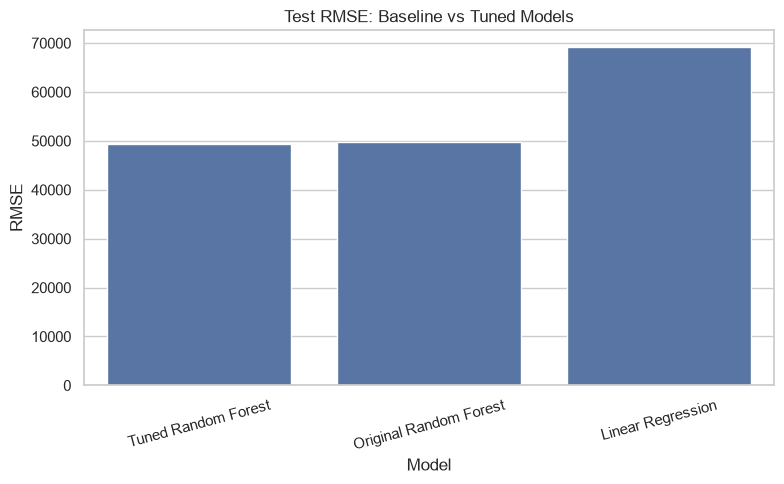

In [25]:
best_forest = rf_search.best_estimator_
tuned_predictions = best_forest.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Original Random Forest", "Tuned Random Forest"],
    "MAE": [linear_mae, forest_mae, tuned_mae],
    "RMSE": [linear_rmse, forest_rmse, tuned_rmse],
    "R2": [linear_r2, forest_r2, tuned_r2]
}).sort_values("RMSE")
display(comparison)

plt.figure(figsize=(8, 5))
sns.barplot(data=comparison, x="Model", y="RMSE")
plt.xticks(rotation=15)
plt.title("Test RMSE: Baseline vs Tuned Models")
plt.tight_layout()
plt.show()
